# Práctica 6 · AHPSort II: clasificación de provincias por nivel de seguridad
**Sistemas de Ayuda a la Decisión · Universidad de Jaén · Pablo Fregenal Castro**

Este cuaderno resuelve los 4 ejercicios de la práctica. Todo el cálculo está en `ahpsort.py`; aquí se llama paso a paso y se muestran tablas, funciones de prioridad y mapas.

**Ejecución:** *Entorno de ejecución → Ejecutar todas*. En Google Colab la primera celda descarga el repositorio (https://github.com/pfc00020-dot/SAD-Pr-ctica6-AHPSort); en local basta con abrir el cuaderno dentro de la carpeta del repositorio.

In [1]:
import os, sys
if not os.path.exists('ahpsort.py'):                      # Google Colab: clonar el repositorio
    !git clone -q https://github.com/pfc00020-dot/SAD-Pr-ctica6-AHPSort.git
    %cd SAD-Pr-ctica6-AHPSort
try:
    import geopandas
except ImportError:
    !pip -q install geopandas
import pandas as pd, matplotlib.pyplot as plt
import ahpsort as A
pd.set_option('display.precision', 4)
os.makedirs('resultados', exist_ok=True)

## 0. Pesos de los criterios (Tabla 4)
Método del autovalor: $A\,w = \lambda_{max}\,w$, $IC = (\lambda_{max}-n)/(n-1)$, $IA = 1{,}98\,(n-2)/n$, $RC = IC/IA$ (válido si $RC<0{,}1$).

In [2]:
ahp = A.pesos_ahp(A.A_CRITERIOS)
display(pd.DataFrame(A.A_CRITERIOS, index=A.CRITERIOS, columns=A.CRITERIOS).round(3).assign(Peso=ahp['pesos']))
print(f"Recíproca: {ahp['reciproca']}  λmáx = {ahp['lambda_max']:.4f}  IC = {ahp['IC']:.4f}  IA = {ahp['IA']:.3f}  RC = {ahp['RC']:.4f}")
print('Juicios válidos (RC < 0,1)' if ahp['RC'] < 0.1 else 'RC >= 0,1: la matriz NO es suficientemente consistente')

,Crímenes,Robos,Vehículos,Orden público,Drogas,Peso
Crímenes,1.000,5.000,3.0,7.0,3.00,0.4668
Robos,0.200,1.000,3.0,0.5,0.25,0.0809
Vehículos,0.333,0.333,1.0,0.2,0.20,0.0549
Orden público,0.143,2.000,5.0,1.0,0.20,0.1170
Drogas,0.333,4.000,5.0,5.0,1.00,0.2803


Recíproca: True  λmáx = 5.7761  IC = 0.1940  IA = 1.188  RC = 0.1633
RC >= 0,1: la matriz NO es suficientemente consistente


## Ejercicio 1 · Andalucía con datos absolutos
Funciones de prioridad local lineales a trozos que unen los RP y CP de la Tabla 6. La prioridad local de una provincia es la interpolación lineal en su tramo:
$p = y_i + (x-x_i)\,\frac{y_{i+1}-y_i}{x_{i+1}-x_i}$

,Crímenes,Robos,Vehículos,Orden público,Drogas
Provincia,,,,,
Almería,23.0,17284.0,2101.0,387.0,267.0
Cádiz,61.0,26571.0,3945.0,722.0,818.0
Córdoba,20.0,14508.0,1691.0,219.0,148.0
Granada,32.0,19139.0,2299.0,368.0,622.0
Huelva,8.0,11222.0,1409.0,156.0,139.0
Jaén,17.0,7548.0,718.0,175.0,129.0
Málaga,58.0,46137.0,6377.0,830.0,934.0
Sevilla,86.0,52849.0,9662.0,716.0,415.0


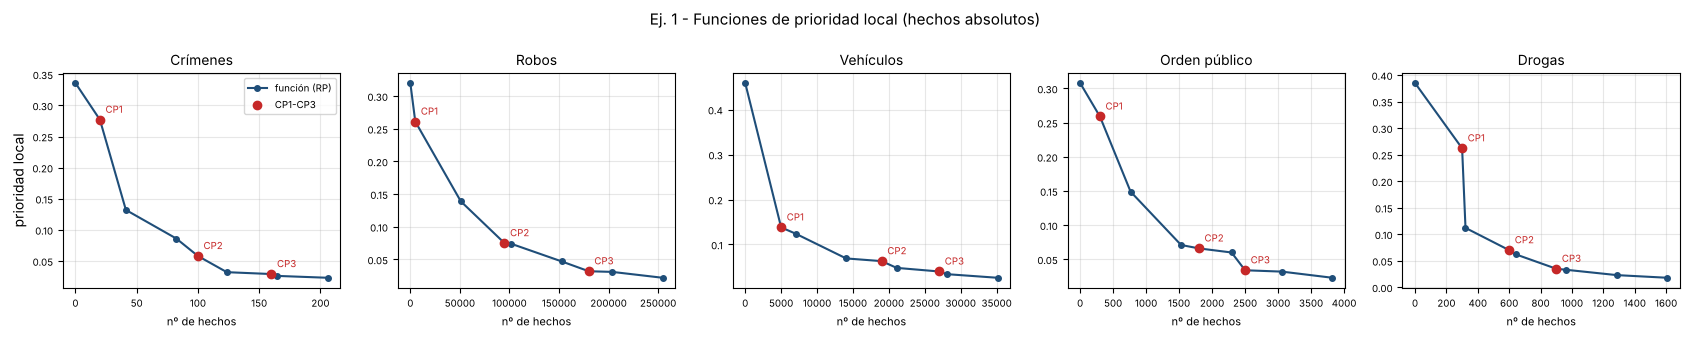

Tabla 7. Prioridades locales y globales de los perfiles centrales


,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
CP1 Alto,0.277,0.261,0.138,0.259,0.262,0.2618
CP2 Medio,0.058,0.075,0.063,0.066,0.070,0.0640
CP3 Bajo,0.029,0.032,0.040,0.034,0.035,0.0321


In [3]:
e1 = A.ejercicio1()
display(e1['datos'])
A.grafica_funciones(e1['modelo'], 'Ej. 1 - Funciones de prioridad local (hechos absolutos)', 'resultados/ej1_funciones.png', 'nº de hechos'); plt.show()
print('Tabla 7. Prioridades locales y globales de los perfiles centrales')
display(e1['modelo'].tabla_cp())

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Provincia,,,,,,,
Huelva,0.3124,0.2445,0.3685,0.2825,0.3280,0.3109,Alto
Jaén,0.2859,0.2542,0.4129,0.2794,0.3321,0.3025,Alto
Córdoba,0.2770,0.2357,0.3504,0.2722,0.3243,0.2904,Alto
Almería,0.2565,0.2284,0.3241,0.2384,0.2755,0.2611,Alto
Granada,0.1949,0.2234,0.3114,0.2429,0.0659,0.1731,Alto
Cádiz,0.1099,0.2037,0.2057,0.1591,0.0436,0.1099,Medio
Sevilla,0.0803,0.1362,0.1034,0.1605,0.0979,0.1004,Medio
Málaga,0.1132,0.1517,0.1285,0.1424,0.0340,0.0984,Medio


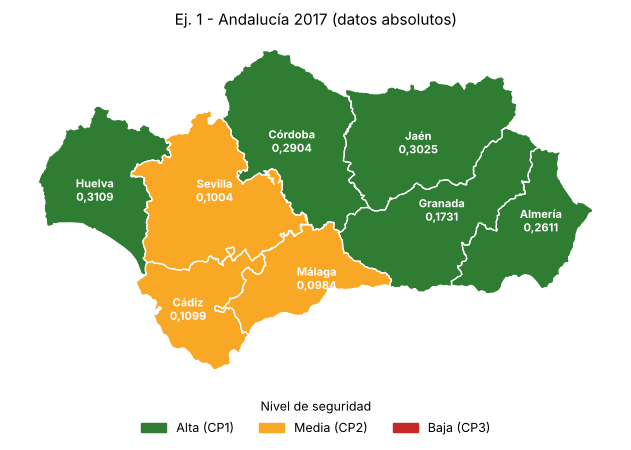

In [4]:
display(e1['resultado'].sort_values('Global', ascending=False))
A.mapa_andalucia(e1['resultado'], 'Ej. 1 - Andalucía 2017 (datos absolutos)', fichero='resultados/ej1_mapa.png'); plt.show()

## Ejercicio 2 · Andalucía normalizada por 10.000 habitantes
Tasa $= \dfrac{\text{hechos}}{\text{habitantes}}\times 10.000$ (población de la tabla *habitantes*). Se reutilizan los pesos; RP y CP se recalculan (RP: 6 puntos equidistantes entre 0 y el máximo; CP: percentiles 20/50/80).

In [5]:
e2 = A.ejercicio2()
display(e2['poblacion'].rename('Habitantes').to_frame().join(e2['tasas']))
print('RP recalculados con la tabla de habitantes'); display(e2['rp_calc'].round(2))
print('RP recalculados con las tasas del fichero nacional 2017 (coinciden con la Tabla 9)'); display(e2['rp_calc_fichero'].round(2))
print('CP recalculados (P20/P50/P80) con habitantes / con el fichero 2017 (Tabla 8)')
display(e2['cp_calc'].round(2)); display(e2['cp_calc_fichero'].round(2))

,Habitantes,Crímenes,Robos,Vehículos,Orden público,Drogas
Provincia,,,,,,
Almería,731792.0,0.3143,236.1873,28.7103,5.2884,3.6486
Cádiz,1245960.0,0.4896,213.2572,31.6623,5.7947,6.5652
Córdoba,776789.0,0.2575,186.7689,21.7691,2.8193,1.9053
Granada,921338.0,0.3473,207.7305,24.9528,3.9942,6.7511
Huelva,525835.0,0.1521,213.4130,26.7955,2.9667,2.6434
Jaén,627190.0,0.2711,120.3463,11.4479,2.7902,2.0568
Málaga,1695651.0,0.3421,272.0902,37.6080,4.8949,5.5082
Sevilla,1947852.0,0.4415,271.3194,49.6034,3.6758,2.1306


RP recalculados con la tabla de habitantes


,Crímenes,Robos,Vehículos,Orden público,Drogas
RP1,0.00,0.00,0.00,0.00,0.00
RP2,0.10,54.42,9.92,1.16,1.35
RP3,0.20,108.84,19.84,2.32,2.70
RP4,0.29,163.25,29.76,3.48,4.05
RP5,0.39,217.67,39.68,4.64,5.40
RP6,0.49,272.09,49.60,5.79,6.75


RP recalculados con las tasas del fichero nacional 2017 (coinciden con la Tabla 9)


,Crímenes,Robos,Vehículos,Orden público,Drogas
RP1,0.00,0.00,0.00,0.00,0.00
RP2,0.10,56.59,9.96,1.17,1.36
RP3,0.20,113.18,19.93,2.33,2.73
RP4,0.30,169.77,29.89,3.50,4.09
RP5,0.39,226.35,39.85,4.66,5.45
RP6,0.49,282.94,49.82,5.83,6.81


CP recalculados (P20/P50/P80) con habitantes / con el fichero 2017 (Tabla 8)


,Crímenes,Robos,Vehículos,Orden público,Drogas
CP1 Alto,0.26,195.15,23.04,2.88,2.09
CP2 Medio,0.33,213.34,27.75,3.84,3.15
CP3 Bajo,0.40,257.27,35.23,5.13,6.14


,Crímenes,Robos,Vehículos,Orden público,Drogas
CP1 Alto,0.26,194.29,22.95,2.87,2.06
CP2 Medio,0.34,215.32,28.44,3.86,3.23
CP3 Bajo,0.41,261.32,36.20,5.32,6.25


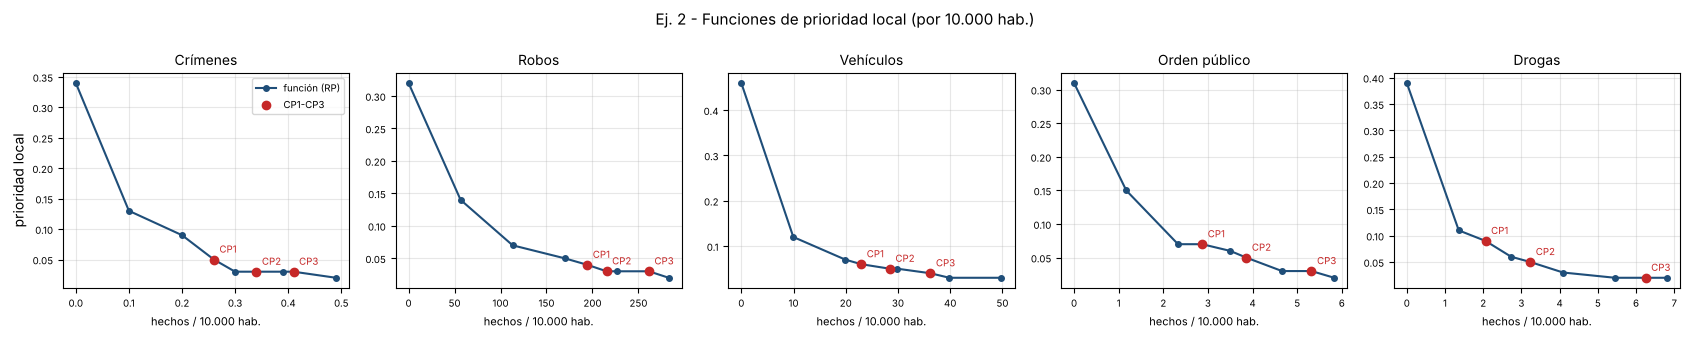

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
CP1 Alto,0.05,0.04,0.06,0.07,0.09,0.0633
CP2 Medio,0.03,0.03,0.05,0.05,0.05,0.0390
CP3 Bajo,0.03,0.03,0.04,0.03,0.02,0.0277


,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Provincia,,,,,,,
Huelva,0.1091,0.0309,0.0530,0.0685,0.0639,0.0823,Alto
Jaén,0.0445,0.0675,0.1125,0.0700,0.0901,0.0658,Alto
Córdoba,0.0517,0.0431,0.0639,0.0700,0.0944,0.0658,Alto
Sevilla,0.0261,0.0254,0.0300,0.0551,0.0868,0.0467,Medio
Almería,0.0300,0.0300,0.0500,0.0300,0.0403,0.0340,Medio
Granada,0.0300,0.0336,0.0564,0.0466,0.0200,0.0309,Bajo
Málaga,0.0300,0.0250,0.0361,0.0300,0.0200,0.0271,Bajo
Cádiz,0.0201,0.0310,0.0472,0.0207,0.0200,0.0225,Bajo


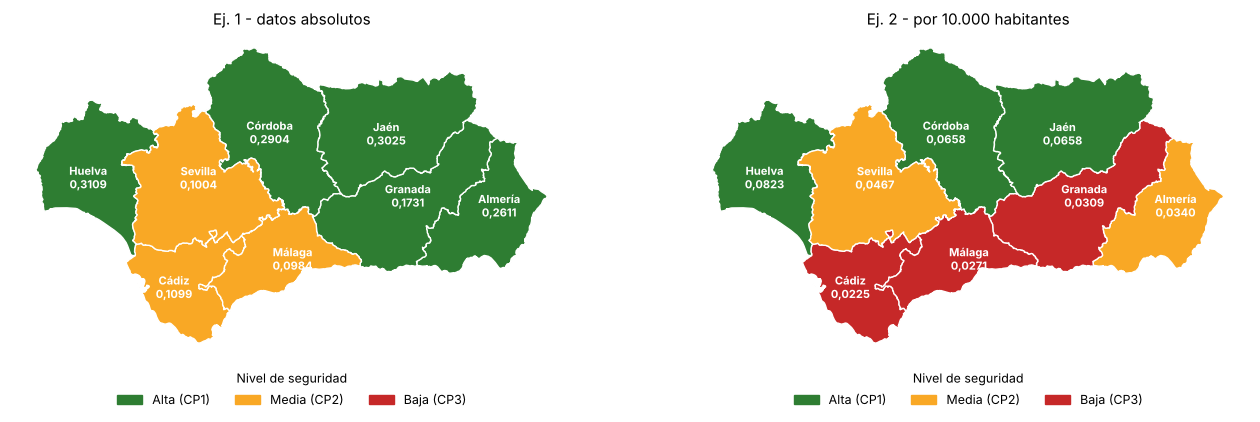

In [6]:
A.grafica_funciones(e2['modelo'], 'Ej. 2 - Funciones de prioridad local (por 10.000 hab.)', 'resultados/ej2_funciones.png', 'hechos / 10.000 hab.'); plt.show()
display(e2['modelo'].tabla_cp())
display(e2['resultado'].sort_values('Global', ascending=False))
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8))
A.mapa_andalucia(e1['resultado'], 'Ej. 1 - datos absolutos', ax=axs[0])
A.mapa_andalucia(e2['resultado'], 'Ej. 2 - por 10.000 habitantes', ax=axs[1])
fig.savefig('resultados/ej2_mapa_comparado.png', dpi=160, bbox_inches='tight'); plt.show()

## Ejercicio 3 · Las 50 provincias españolas (2017)
(a) Verificación de la normalización: con los hechos absolutos de Andalucía, la población implícita `hechos / tasa × 10.000` debe ser la misma en los 5 criterios.
(b) RP = 6 puntos equidistantes en [0, máximo nacional]; CP = percentiles 20/50/80 de las 50 provincias. Las prioridades de los CP se interpolan en la función de los RP (Tabla 13 → Tabla 14).

,Crímenes,Robos,Vehículos,Orden público,Drogas,Habitantes (tabla)
Provincia,,,,,,
Almería,706672.0,706672.0,706672.0,706672.0,706672.0,731792.0
Cádiz,1239435.0,1239435.0,1239435.0,1239435.0,1239435.0,1245960.0
Córdoba,788219.0,788219.0,788219.0,788219.0,788219.0,776789.0
Granada,912938.0,912938.0,912938.0,912938.0,912938.0,921338.0
Huelva,518930.0,518930.0,518930.0,518930.0,518930.0,525835.0
Jaén,643484.0,643484.0,643484.0,643484.0,643484.0,627190.0
Málaga,1630615.0,1630615.0,1630615.0,1630615.0,1630615.0,1695651.0
Sevilla,1939527.0,1939527.0,1939527.0,1939527.0,1939527.0,1947852.0


RP recalculados (Tabla 12)


,Crímenes,Robos,Vehículos,Orden público,Drogas
RP1,0.00,0.00,0.00,0.00,0.00
RP2,0.15,81.29,10.80,1.18,1.36
RP3,0.30,162.59,21.59,2.35,2.73
RP4,0.44,243.88,32.39,3.53,4.09
RP5,0.59,325.17,43.19,4.70,5.45
RP6,0.74,406.46,53.98,5.88,6.81


CP recalculados (Tabla 11)


,Crímenes,Robos,Vehículos,Orden público,Drogas
CP1 Alto,0.17,129.18,7.42,2.73,1.46
CP2 Medio,0.25,179.37,13.69,3.38,2.00
CP3 Bajo,0.36,268.99,30.94,4.52,2.77


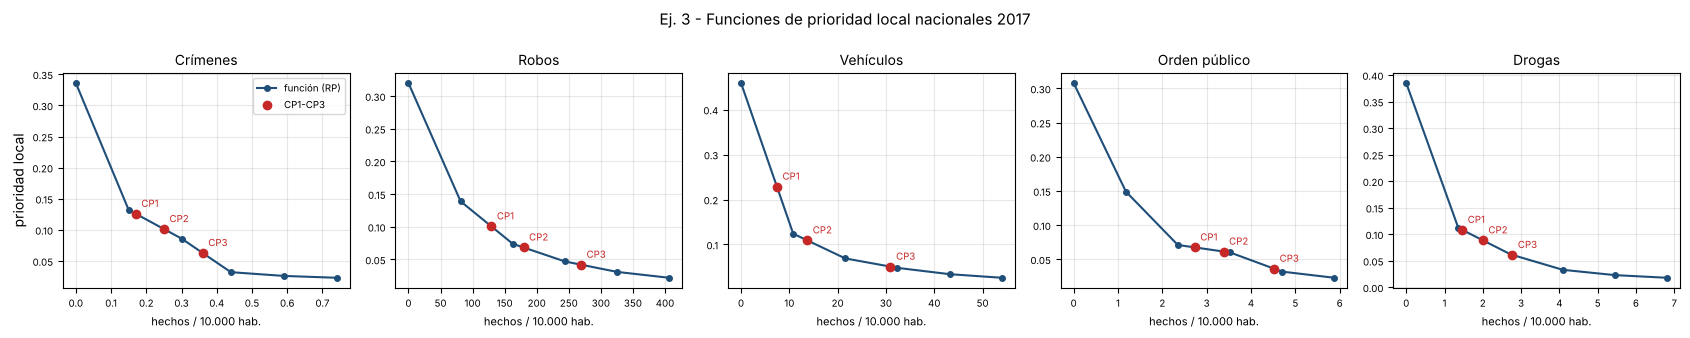

Tabla 14


,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
CP1 Alto,0.1259,0.1007,0.2288,0.0675,0.1084,0.1177
CP2 Medio,0.1013,0.0684,0.1093,0.0614,0.0886,0.0909
CP3 Bajo,0.0629,0.0421,0.0508,0.0363,0.0611,0.0569


In [7]:
e3 = A.ejercicio3()
display(e3['pob_implicita'].round(0))
print('RP recalculados (Tabla 12)'); display(e3['rp_calc'].round(2))
print('CP recalculados (Tabla 11)'); display(e3['cp_calc'].round(2))
A.grafica_funciones(e3['modelo'], 'Ej. 3 - Funciones de prioridad local nacionales 2017', 'resultados/ej3_funciones.png', 'hechos / 10.000 hab.'); plt.show()
print('Tabla 14'); display(e3['modelo'].tabla_cp())

,cod,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Provincia,,,,,,,,
Soria,42,0.3360,0.1019,0.2287,0.1002,0.1366,0.2277,Alto
Palencia,34,0.3360,0.1212,0.3375,0.0537,0.1058,0.2211,Alto
Burgos,09,0.2980,0.0776,0.1140,0.0463,0.0862,0.1812,Alto
Cuenca,16,0.2676,0.0768,0.1054,0.1035,0.0992,0.1768,Alto
Lugo,27,0.2137,0.1247,0.1559,0.0686,0.1069,0.1564,Alto
Valladolid,47,0.0833,0.0718,0.1757,0.0793,0.2733,0.1402,Alto
León,24,0.1125,0.0723,0.1272,0.0664,0.2135,0.1330,Alto
Segovia,40,0.1596,0.1030,0.2618,0.0639,0.0977,0.1321,Alto
Ávila,05,0.1667,0.1004,0.2216,0.0633,0.0844,0.1292,Alto


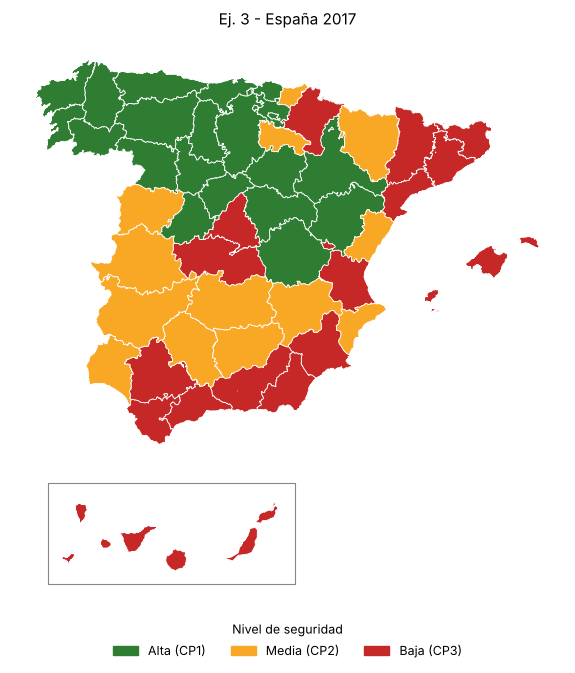

In [8]:
display(e3['resultado'].sort_values('Global', ascending=False))
A.mapa_espana(e3['resultado'], 'Ej. 3 - España 2017', fichero='resultados/ej3_mapa.png'); plt.show()

## Ejercicio 4 · 2023 con la calibración de 2017
Mismos pesos, CP, RP y funciones; las tasas fuera de [RP1, RP6] se truncan (reciben la prioridad del extremo).

In [9]:
e4 = A.ejercicio4()
print(f"Comprobación de la normalización 2023: error máximo = {e4['err_norm']:.1e}")
f = e4['fuera_rango']
for c in A.CRITERIOS:
    if f[c].any(): print(f'Truncadas en {c}: ' + ', '.join(f.index[f[c]]))
display(e4['resultado'].sort_values('Global', ascending=False))

Comprobación de la normalización 2023: error máximo = 5.7e-14
Truncadas en Orden público: Araba/Álava, Alicante, Almería, Illes Balears, Cádiz, Castellón, Girona, Gipuzkoa, Madrid, Málaga, Murcia, Navarra, Soria, Tarragona, Toledo, Valencia, Zaragoza
Truncadas en Drogas: Girona, Granada, Málaga


,cod,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Provincia,,,,,,,,
Teruel,44,0.2354,0.1713,0.3581,0.0667,0.0915,0.1769,Alto
Ourense,32,0.2020,0.1265,0.1138,0.0502,0.1609,0.1618,Alto
Segovia,40,0.2484,0.1254,0.1933,0.0241,0.0584,0.1559,Alto
Burgos,09,0.1837,0.1023,0.1204,0.0241,0.0778,0.1253,Alto
Cáceres,10,0.1305,0.1425,0.2941,0.0621,0.0797,0.1182,Alto
Bizkaia,48,0.1357,0.0551,0.3426,0.0248,0.0937,0.1158,Alto
Salamanca,37,0.1311,0.0988,0.0904,0.0616,0.0869,0.1057,Alto
Asturias,33,0.1139,0.1190,0.1983,0.0291,0.0927,0.1031,Medio
Zamora,49,0.1227,0.1306,0.2707,0.0567,0.0484,0.1029,Medio


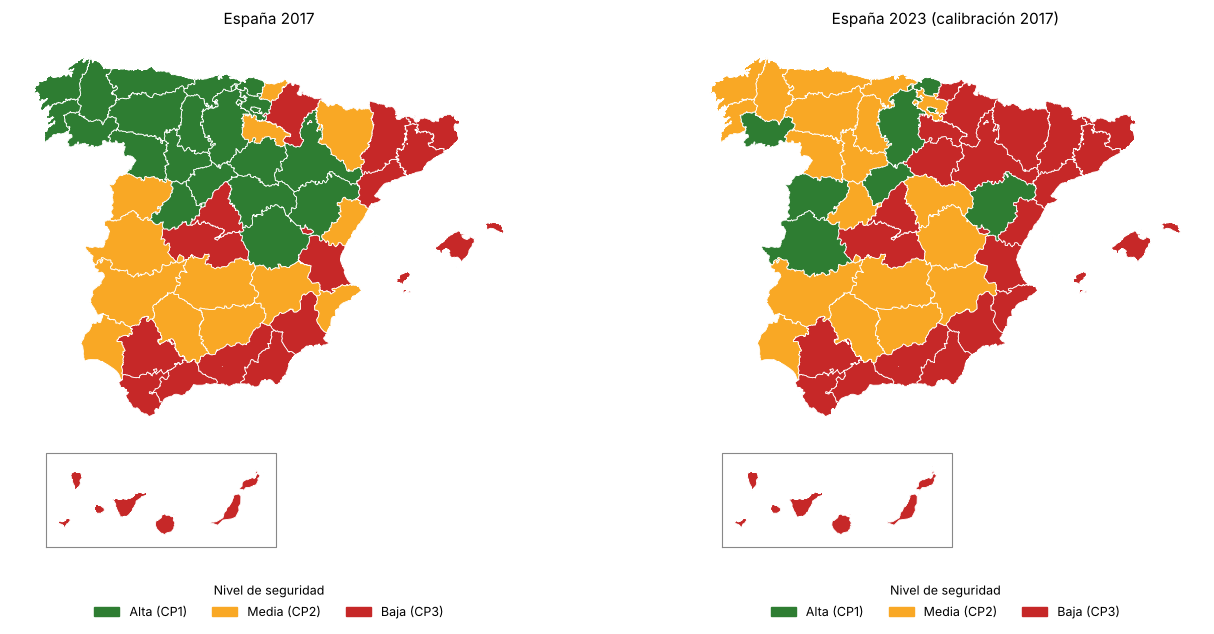

Tabla de transición por provincias


,cod,Global 2017,Clase 2017,Global 2023,Clase 2023,Cambio
Provincia,,,,,,
Araba/Álava,01,0.1147,Alto,0.0942,Medio,empeora
Albacete,02,0.0746,Medio,0.0744,Medio,=
Alicante,03,0.0751,Medio,0.0399,Bajo,empeora
Almería,04,0.0564,Bajo,0.0336,Bajo,=
Ávila,05,0.1292,Alto,0.0889,Medio,empeora
Badajoz,06,0.0884,Medio,0.0840,Medio,=
Illes Balears,07,0.0515,Bajo,0.0325,Bajo,=
Barcelona,08,0.0577,Bajo,0.0411,Bajo,=
Burgos,09,0.1812,Alto,0.1253,Alto,=


Matriz de cambios entre clases (filas 2017, columnas 2023)


2023,Alto,Medio,Bajo
2017,,,
Alto,5,13,2
Medio,2,6,5
Bajo,0,0,17


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(16, 7))
A.mapa_espana(e3['resultado'], 'España 2017', ax=axs[0])
A.mapa_espana(e4['resultado'], 'España 2023 (calibración 2017)', ax=axs[1])
fig.savefig('resultados/ej4_mapas_2017_2023.png', dpi=160, bbox_inches='tight'); plt.show()
print('Tabla de transición por provincias'); display(e4['transicion'])
print('Matriz de cambios entre clases (filas 2017, columnas 2023)'); display(e4['matriz'])